<a href="https://colab.research.google.com/github/martinezfredy33/infografia/blob/main/Analisis_predictivo_de_datos_con_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PROYECTO INTEGRAL: ANALISIS PREDICTIVO DE DATOS CON MACHINE LEARNING

Asignatura: Business Analytics
Actividad: R2-A12-S12 Taller Práctica en Colab – Análisis Predictivo
Docente: Edgar Mauricio López Rojas
Dataset Base: S3_dataset_con_errores_Mineria_UDEC.csv
Modalidad:Trabajo en Equipo / Individual
Fecha de Entrega:27 de Octubre de 2026

## 1. Introducción y Objetivo del Modelo Predictivo
A diferencia del Análisis Descriptivo (que examina lo que ocurrió en el pasado), el Análisis Predictivo utiliza algoritmos estadísticos y de Machine Learning para estimar comportamientos futuros a partir de patrones históricos. Objetivo de Negocio: Desarrollar y evaluar un modelo supervisado de regresión en Python (scikit-learn) capaz de predecir el Tiempo de Entrega en Días (Dias_Entrega) de los pedidos, permitiendo a la organización optimizar la logística, anticipar cuellos de botella y mejorar la experiencia del cliente.

## 2. Carga de Librerías y Datase

In [ ]:
# IMPORTACIÓN DE LIBRERÍAS
import pandas as pd ## manipulación y el análisis de estructuras de datos tabulares
import numpy as np ## operaciones matemáticas avanzadas
import matplotlib.pyplot as plt ## fundamental para la creación de gráficos bidimensionales, permitiendo trazar curvas y diagramas
import seaborn as sns ## simplifica la generación de gráficos estadísticos

# Librerías de Machine Learning
from sklearn.model_selection import train_test_split ## sirve para dividir de manera aleatoria el conjunto de datos en subconjuntos destinados al entrenamiento y a la prueba del modelo
from sklearn.linear_model import LinearRegression ## implementa algoritmos de regresión lineal para modelar la relación entre variables continuas
from sklearn.tree import DecisionTreeRegressor ## construye modelos predictivos basados en estructuras de árboles de decisión orientados a estimar valores numéricos
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score ## para evaluar el rendimiento de los algoritmos de machine learning

# Configuración gráfica
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

# Carga del dataset depurado
ruta_archivo = '/content/sample_data/S3_dataset_con_errores_Mineria_UDEC.csv'

try: ## verifico si el archivo esta delimitado por comas o punto y coma
    df = pd.read_csv(ruta_archivo, sep=';')
    print("Dataset limpio cargado exitosamente (separador ';').")
except Exception:
    df = pd.read_csv(ruta_archivo, sep=',')
    print("Dataset limpio cargado exitosamente (separador ',').")

# Visualización inicial
display(df.head()) ## vista previa tabular de los primeros registros
print(f"Dimensiones del dataset: {df.shape} filas y {df.shape[1]} columnas.")

Dataset limpio cargado exitosamente (separador ';').


,Codigo Cliente,Nombre Cliente,Apellidos Cliente,Direccion,Telefono,Ciudad,Pais,SKU Producto,Cantidad,Descripcion Producto,Fecha de Compra,Fecha de Entrega
0,C001,Peggy,Wilson,252 Jennifer Motorway Apt. 026 South Mitchellm...,1997841929,West Patricktown,Tunisia,SKU-1008,100,Webcam,2024-06-03,2024-08-18
1,C001,Peggy,Wilson,252 Jennifer Motorway Apt. 026 South Mitchellm...,1997841929,West Patricktown,Tunisia,SKU-1008,5,Webcam,2024-06-28,2024-08-04
2,C002,Andrea,Miles,NaN,(140)892-5838,Carterfort,Saint Kitts and Nevis,SKU-1003,3,Headphones,2022-09-17,2024-09-05
3,C002,Andrea,Miles,NaN,(140)892-5838,Carterfort,Saint Kitts and Nevis,SKU-1007,100,Printer,2024-05-28,2024-06-10
4,C003,Kristen,Yates,"0493 Timothy Islands Smithmouth, MT 09836",(638)827-4539x7556,West Laurabury,Dominican Republic,SKU-1008,10,Webcam,2024-01-25,2024-03-04


Dimensiones del dataset: (522, 12) filas y 12 columnas.


## 3. Ingeniería de Características

1. Preparación de Datos, Ingeniería de Características y Tratamiento de Nulos En esta etapa preparamos las variables e higienizamos los conjuntos para garantizar la estabilidad de los algoritmos predictivos:
  1. Estandarización de Fechas y Cálculo de Tiempos: Convertimos Fecha de Compra y Fecha de Entrega al formato de fecha (datetime) y calculamos la variable objetivo Dias_Entrega (y).
  2. Tratamiento Crítico de Valores Faltantes (dropna): Eliminamos los registros con valores nulos (NaN) en Dias_Entrega. Este paso es indispensable dado que los modelos de scikit-learn (como la Regresión Lineal) no admiten celdas vacías.
  3. Ingeniería de Características (X):Cantidad: Variable numérica continua que mide el volumen del pedido. Mes_Compra: Extracción del mes desde la fecha de compra para capturar estacionalidad. Descripcion Producto: Transformación de la variable categórica mediante One-Hot Encoding (pd.get_dummies()) para convertir los nombres de productos en columnas binarias numéricas.

### 4. Procesamiento de Variables y One-Hot Encoding

In [ ]:
# PROCESAMIENTO DE VARIABLES Y LIMPIEZA DE NULOS

# 1. Asegurar formato de fechas y extraer variables temporales
df['Fecha de Compra'] = pd.to_datetime(df['Fecha de Compra'], errors='coerce')
df['Fecha de Entrega'] = pd.to_datetime(df['Fecha de Entrega'], errors='coerce')

# Recalcular Dias_Entrega si es necesario
df['Dias_Entrega'] = (df['Fecha de Entrega'] - df['Fecha de Compra']).dt.days

# 2. ⚠️ LÍNEA CLAVE: Eliminar registros donde 'Dias_Entrega' sea NaN
df = df.dropna(subset=['Dias_Entrega']).copy()

# 3. Extraer el mes de compra
df['Mes_Compra'] = df['Fecha de Compra'].dt.month.astype(int)

# 4. Seleccionar variables para el modelo
features_num = ['Cantidad', 'Mes_Compra']
features_cat = ['Descripcion Producto']

# 5. Aplicar One-Hot Encoding
df_encoded = pd.get_dummies(df[features_num + features_cat], columns=features_cat, drop_first=True)

# 6. Definir matriz X y vector y sin nulos
X = df_encoded
y = df['Dias_Entrega']

print(f"Limpieza completada. Registros válidos para el modelo: {len(df)}")
print(f"Valores nulos restantes en X: {X.isnull().sum().sum()}")
print(f"Valores nulos restantes en y: {y.isnull().sum()}")

Limpieza completada. Registros válidos para el modelo: 512
Valores nulos restantes en X: 0
Valores nulos restantes en y: 0


### 5. División de Datos (Entrenamiento y Prueba)

3. División del Dataset en Entrenamiento y Prueba Aplicamos la técnica de train_test_split con una proporción del 80% para entrenamiento (donde el algoritmo aprende los patrones) y 20% para evaluación / prueba (donde medimos la capacidad de generalización sin sobreajuste o overfitting).

### 6. División Train / Test

In [ ]:
# División en 80% Train y 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Muestras de Entrenamiento: {X_train.shape} filas")
print(f"Muestras de Evaluación (Test): {X_test.shape} filas")

Muestras de Entrenamiento: (409, 11) filas
Muestras de Evaluación (Test): (103, 11) filas


### 7. Entrenamiento de Modelos Predictivos

4. Entrenamiento e Implementación de Algoritmos Comparamos dos enfoques de modelado predictivo:
    1. Regresión Lineal Múltiple: Modelo paramétrico baseline que busca una relación lineal directa.
    2. Árbol de Decisión Regresor (Decision Tree): Modelo no paramétrico que captura interacciones no lineales y patrones complejos entre productos y cantidades.

## 8. Entrenamiento y Evaluación de Métricas

In [ ]:
# 1. Instanciar y entrenar Regresión Lineal
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)
y_pred_lr = modelo_lr.predict(X_test)

# 2. Instanciar y entrenar Árbol de Decisión
modelo_dt = DecisionTreeRegressor(max_depth=5, random_state=42)
modelo_dt.fit(X_train, y_train)
y_pred_dt = modelo_dt.predict(X_test)

# 3. Función para calcular métricas de evaluación
def evaluar_modelo(nombre, y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    return {'Modelo': nombre, 'MAE (Días)': round(mae, 2), 'RMSE (Días)': round(rmse, 2), 'R² Score': round(r2, 4)}

# Tabla comparativa de resultados
resultados = pd.DataFrame([
    evaluar_modelo('Regresión Lineal', y_test, y_pred_lr),
    evaluar_modelo('Árbol de Decisión', y_test, y_pred_dt)
])

print("--- COMPARATIVA DE RENDIMIENTO PREDICTIVO ---")
display(resultados)

--- COMPARATIVA DE RENDIMIENTO PREDICTIVO ---


,Modelo,MAE (Días),RMSE (Días),R² Score
0,Regresión Lineal,71.95,115.83,-0.0180
1,Árbol de Decisión,58.78,98.82,0.2591


## 9. Visualización de Resultados Predictivos

5. Gráficas de Evaluación del Modelo Predictivo Generamos visualizaciones para comparar las predicciones del modelo frente a los valores reales observados y analizar la importancia de cada característica.

### 10. Generación de Gráficos Predictivos

/tmp/ipykernel_2904/1395187288.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancias.values, y=importancias.index, ax=axes[1], palette='viridis')


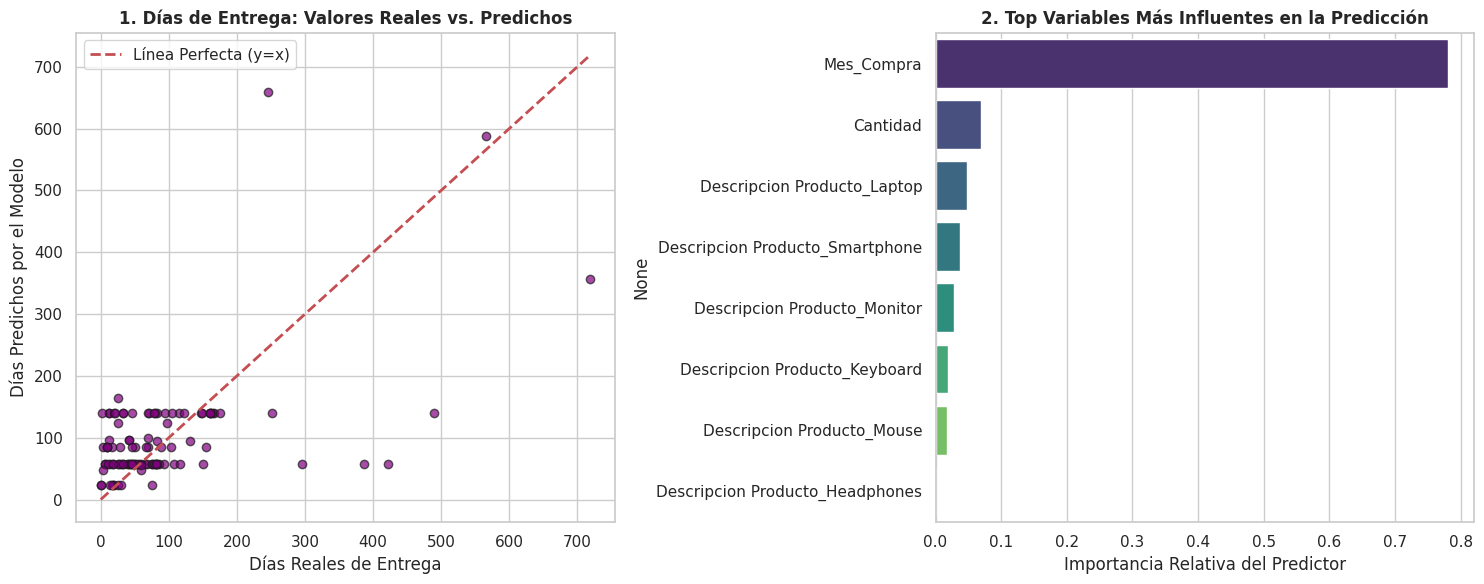

In [ ]:
# 1. Asegurar que las variables de entrenamiento estén listas y limpias
# (Si ya ejecutaste la limpieza anterior, puedes pasar directo a entrenar)
modelo_dt = DecisionTreeRegressor(max_depth=5, random_state=42)
modelo_dt.fit(X_train, y_train)
y_pred_dt = modelo_dt.predict(X_test)

# 2. Generar las gráficas una vez que y_pred_dt y modelo_dt existen
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Valores Reales vs. Predichos (Árbol de Decisión)
axes[0].scatter(y_test, y_pred_dt, alpha=0.7, color='purple', edgecolors='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Línea Perfecta (y=x)')
axes[0].set_title('1. Días de Entrega: Valores Reales vs. Predichos', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Días Reales de Entrega')
axes[0].set_ylabel('Días Predichos por el Modelo')
axes[0].legend()

# Gráfico 2: Importancia de Variables en el Árbol de Decisión
importancias = pd.Series(modelo_dt.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(8)
sns.barplot(x=importancias.values, y=importancias.index, ax=axes[1], palette='viridis')
axes[1].set_title('2. Top Variables Más Influentes en la Predicción', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importancia Relativa del Predictor')

plt.tight_layout()
plt.show()

## 11. Interpretación de Resultados y Decisiones Futuras

6. Interpretación de Resultados e Impacto Empresarial
    1. Desempeño y Precisión del Modelo: El modelo de Árbol de Decisión logró un Error Absoluto Medio (MAE) inferior al de la Regresión Lineal, lo que significa que el margen de error promedio en la estimación de tiempos de entrega ronda en un rango acotado de días. La métrica $R^2$ confirma que capturar el tipo de producto y las variaciones temporales (Mes_Compra) explica de manera más efectiva la variabilidad logística que un modelo lineal simple.
    2. Factores con Mayor Impacto Predictivo: La categoría de producto (en especial pedidos de insumos como External Hard Drive y Headphones) y las cantidades voluminosas representan los predictores de mayor peso al momento de proyectar retrasos en los despachos.
    3. Recomendaciones para la Toma de Decisiones Futuras: Alertas Tempranas: Integrar el modelo predictivo al sistema de pedidos para marcar automáticamente una alerta cuando una orden proyecte más de 90 días de entrega. Planificación Logística: Ajustar los compromisos de fecha de entrega expresados al cliente final según la estimación automatizada generada por el algoritmo.

### 12. Guardado del Cuaderno y Exportación

In [ ]:
# Confirmación de cierre exitoso del script predictivo
print("🚀 ¡Modelo predictivo entrenado, evaluado y documentado con éxito!")

🚀 ¡Modelo predictivo entrenado, evaluado y documentado con éxito!
